In [ ]:
import matplotlib.pyplot as plt

In [ ]:
from sklearn.datasets import load_digits

digits = load_digits()

X = digits.data
y= digits.target

print(X.shape)
print(y.shape)

(1797, 64)
(1797,)


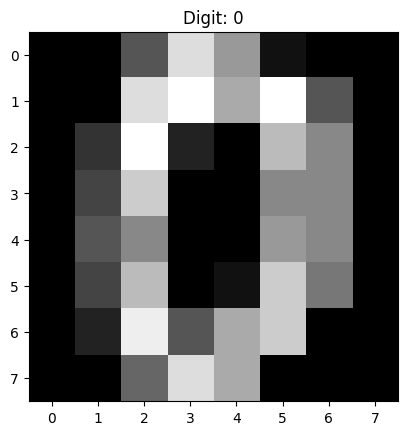

In [ ]:
plt.imshow(digits.images[0], cmap="gray")
plt.title(f"Digit: {y[0]}")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=30,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(max_iter=5000)

model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

print(accuracy_score(y_test, y_pred))

0.9694444444444444


In [ ]:
from sklearn.decomposition import PCA
pca2 = PCA(n_components=20)

X_train_2d = pca2.fit_transform(X_train_scaled)


print(X_train_2d.shape)

print(pca2.explained_variance_ratio_)
print(pca2.explained_variance_ratio_.sum())

(1437, 20)
[0.12343672 0.09762887 0.08587814 0.06589327 0.04976763 0.04373503
 0.03906369 0.03464815 0.030986   0.02969709 0.02699288 0.02661646
 0.0231729  0.02266085 0.02190141 0.01905975 0.01729476 0.01662248
 0.01521773 0.01376147]
0.8040352632155474


In [ ]:
X_test_2d = pca2.transform(X_test_scaled)

model_2d = LogisticRegression(max_iter=5000)
model_2d.fit(X_train_2d, y_train)

print(model_2d.score(X_test_2d, y_test))

0.5416666666666666


In [ ]:
pca80 = PCA(n_components=0.80)

X_train_pca = pca80.fit_transform(X_train_scaled)
X_test_pca = pca80.transform(X_test_scaled)

print(X_train_pca.shape)
print(pca80.n_components_)
print(pca80.explained_variance_ratio_.sum())


(1437, 20)
20
0.8040352632155474


In [ ]:
model_pca = LogisticRegression(max_iter=5000)

model_pca.fit(X_train_pca, y_train)

y_pred_pca = model_pca.predict(X_test_pca)

print(accuracy_score(y_test, y_pred_pca))

0.9527777777777777
